# Tech Challenge - Fase 1: diagnóstico de câncer de mama

**Autores:** Matheus Silva Vilas Boas, Tatiane Pereira Rocha e Cyro Pereira Silva Souza

Este notebook demonstra o projeto passo a passo usando os módulos da pasta `src`. O objetivo é classificar exames de punção aspirativa por agulha fina (PAAF) de nódulos de mama como **maligno** ou **benigno**, como apoio à decisão médica.

Dataset: [Breast Cancer Wisconsin (Diagnostic) no Kaggle](https://www.kaggle.com/datasets/uciml/breast-cancer-wisconsin-data).

O mesmo fluxo roda de ponta a ponta com `python -m src.treinar`, que também gera o relatório técnico em PDF.

In [1]:
import sys

sys.path.append("..")

import pandas as pd

from src import interpretacao, visualizacao
from src.avaliacao import escolher_melhor_modelo
from src.dados import carregar_dados, resumo_dos_dados, separar_x_y
from src.preprocessamento import dividir_dados, limpar_dados
from src.treinar import avaliar_no_teste, treinar_e_comparar

## 1. Carga dos dados

A função `carregar_dados` lê o CSV, padroniza os nomes das colunas e remove as colunas que não ajudam no diagnóstico (o `id` do paciente e a coluna vazia que vem no arquivo original do Kaggle).

In [2]:
df = carregar_dados()
df.head()

,diagnosis,radius_mean,texture_mean,perimeter_mean,area_mean,smoothness_mean,compactness_mean,concavity_mean,concave_points_mean,symmetry_mean,...,radius_worst,texture_worst,perimeter_worst,area_worst,smoothness_worst,compactness_worst,concavity_worst,concave_points_worst,symmetry_worst,fractal_dimension_worst
0,M,17.99,10.38,122.80,1001.0,0.11840,0.27760,0.3001,0.14710,0.2419,...,25.38,17.33,184.60,2019.0,0.1622,0.6656,0.7119,0.2654,0.4601,0.11890
1,M,20.57,17.77,132.90,1326.0,0.08474,0.07864,0.0869,0.07017,0.1812,...,24.99,23.41,158.80,1956.0,0.1238,0.1866,0.2416,0.1860,0.2750,0.08902
2,M,19.69,21.25,130.00,1203.0,0.10960,0.15990,0.1974,0.12790,0.2069,...,23.57,25.53,152.50,1709.0,0.1444,0.4245,0.4504,0.2430,0.3613,0.08758
3,M,11.42,20.38,77.58,386.1,0.14250,0.28390,0.2414,0.10520,0.2597,...,14.91,26.50,98.87,567.7,0.2098,0.8663,0.6869,0.2575,0.6638,0.17300
4,M,20.29,14.34,135.10,1297.0,0.10030,0.13280,0.1980,0.10430,0.1809,...,22.54,16.67,152.20,1575.0,0.1374,0.2050,0.4000,0.1625,0.2364,0.07678


In [3]:
resumo_dos_dados(df)

{'linhas': 569,
 'colunas': 31,
 'valores_ausentes': 0,
 'linhas_duplicadas': 0,
 'malignos': 212,
 'benignos': 357}

São 569 exames e 30 variáveis numéricas. Para cada uma das 10 características do núcleo da célula (raio, textura, perímetro, área, suavidade, compacidade, concavidade, pontos côncavos, simetria e dimensão fractal) existem três medidas: média (`_mean`), erro padrão (`_se`) e pior valor (`_worst`).

## 2. Limpeza

A limpeza remove linhas duplicadas, padroniza o diagnóstico, descarta diagnósticos diferentes de M e B e transforma valores negativos ou não numéricos em ausentes. Nesta base nada precisou ser removido, mas a etapa fica no pipeline para dados novos.

In [4]:
df = limpar_dados(df)
resumo_dos_dados(df)

{'linhas': 569,
 'colunas': 31,
 'valores_ausentes': 0,
 'linhas_duplicadas': 0,
 'malignos': 212,
 'benignos': 357}

## 3. Exploração dos dados

### Estatísticas descritivas

In [5]:
visualizacao.estatisticas_descritivas(df)

,count,mean,std,min,25%,50%,75%,max
radius_mean,569.0,14.1273,3.5240,6.9810,11.7000,13.3700,15.7800,28.1100
texture_mean,569.0,19.2896,4.3010,9.7100,16.1700,18.8400,21.8000,39.2800
perimeter_mean,569.0,91.9690,24.2990,43.7900,75.1700,86.2400,104.1000,188.5000
area_mean,569.0,654.8891,351.9141,143.5000,420.3000,551.1000,782.7000,2501.0000
smoothness_mean,569.0,0.0964,0.0141,0.0526,0.0864,0.0959,0.1053,0.1634
compactness_mean,569.0,0.1043,0.0528,0.0194,0.0649,0.0926,0.1304,0.3454
concavity_mean,569.0,0.0888,0.0797,0.0000,0.0296,0.0615,0.1307,0.4268
concave_points_mean,569.0,0.0489,0.0388,0.0000,0.0203,0.0335,0.0740,0.2012
symmetry_mean,569.0,0.1812,0.0274,0.1060,0.1619,0.1792,0.1957,0.3040
fractal_dimension_mean,569.0,0.0628,0.0071,0.0500,0.0577,0.0615,0.0661,0.0974


As escalas são muito diferentes entre as variáveis (a área chega a 2.500 e a suavidade fica perto de 0,1). Por isso o pipeline usa `StandardScaler` antes dos modelos.

### Média das principais variáveis por diagnóstico

In [6]:
visualizacao.media_por_classe(df)

diagnosis,Benigno,Maligno,razao_maligno_benigno
radius_mean,12.147,17.463,1.438
texture_mean,17.915,21.605,1.206
perimeter_mean,78.075,115.365,1.478
area_mean,462.790,978.376,2.114
concavity_mean,0.046,0.161,3.491
concave_points_mean,0.026,0.088,3.421


Os tumores malignos têm núcleos bem maiores e mais irregulares: a área média é cerca de duas vezes maior e a concavidade mais de três vezes maior do que nos benignos.

### Balanço das classes

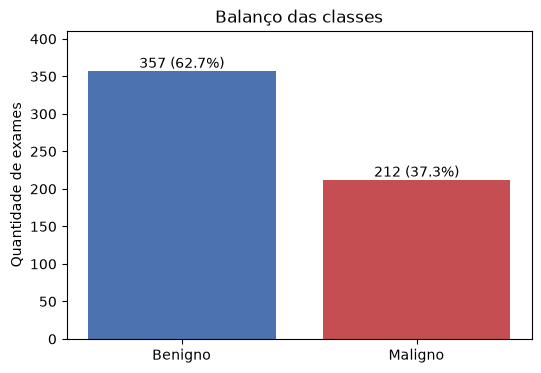

In [7]:
visualizacao.grafico_balanco_classes(df)

Cerca de 63% dos exames são benignos e 37% malignos. Por isso a divisão dos dados é estratificada e a métrica principal não é a accuracy.

### Distribuições

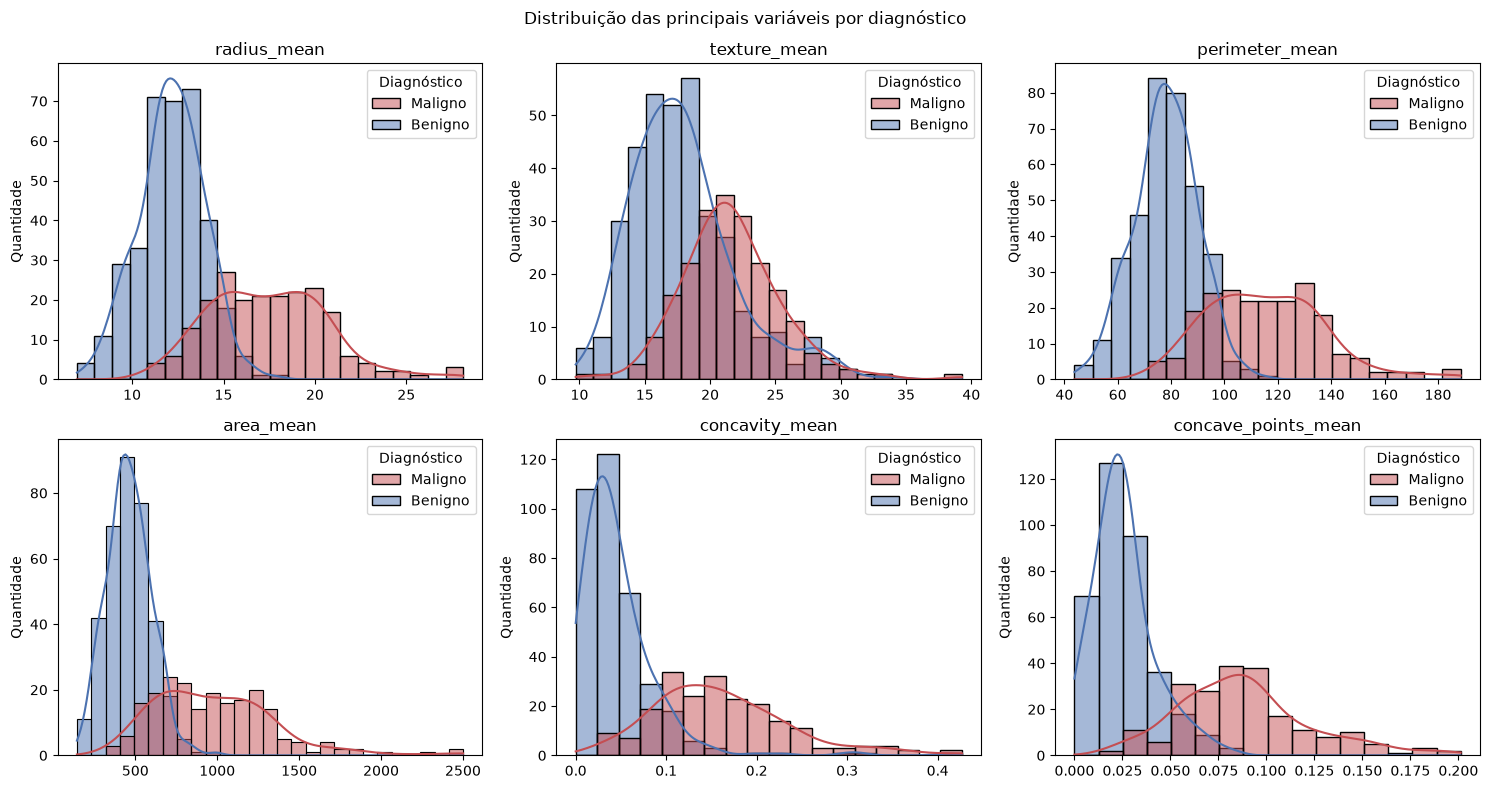

In [8]:
visualizacao.grafico_distribuicoes(df)

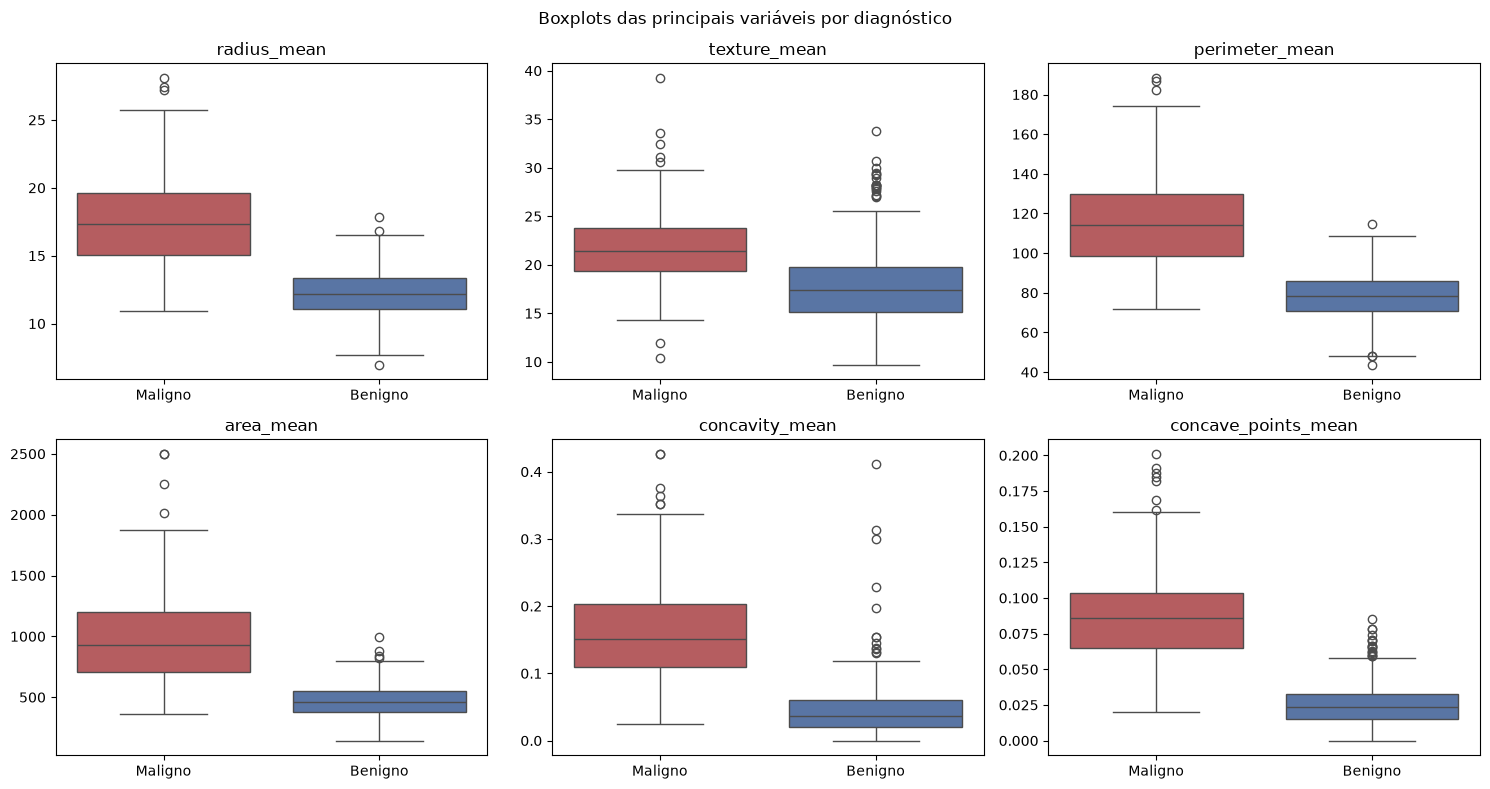

In [9]:
visualizacao.grafico_boxplots(df)

Raio, perímetro, área, concavidade e pontos côncavos separam bem as classes. A textura tem bastante sobreposição. Várias distribuições são assimétricas e têm valores extremos, mas são medições plausíveis e por isso foram mantidas.

## 4. Análise de correlação

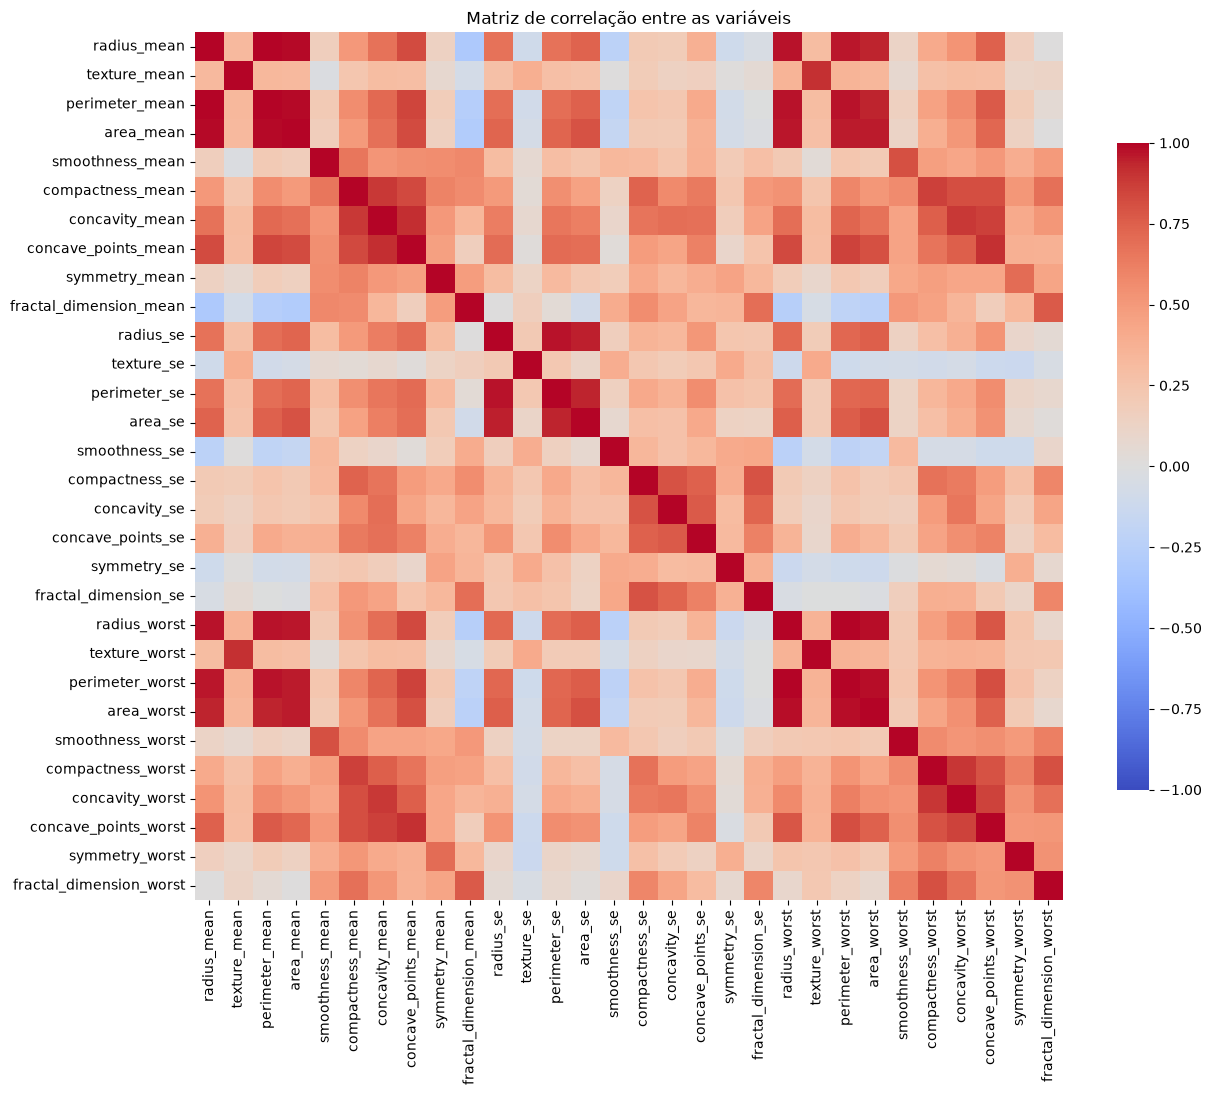

In [10]:
visualizacao.grafico_correlacao(df)

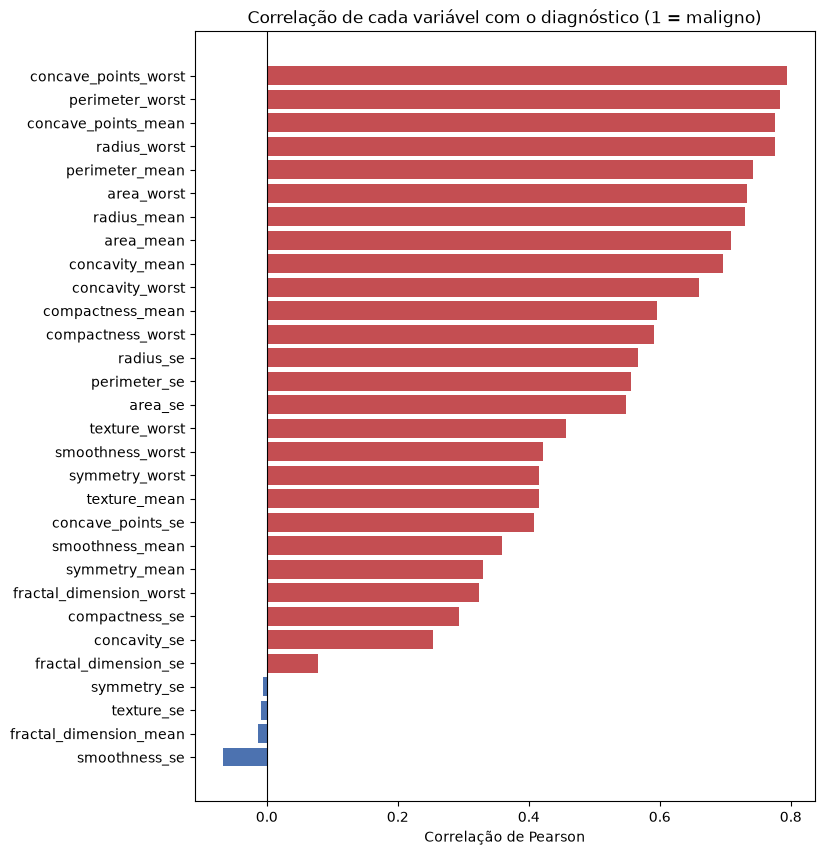

In [11]:
visualizacao.grafico_correlacao_com_alvo(df)

Raio, perímetro e área são praticamente a mesma informação (correlação entre 0,94 e 0,99). As variáveis mais ligadas ao diagnóstico maligno são as de pontos côncavos, perímetro, raio e área, principalmente nas medidas `_worst`. Mantivemos todas as variáveis e deixamos a interpretação do modelo mostrar quais pesam mais.

## 5. Separação em treino, validação e teste

Divisão estratificada 70/15/15 com semente fixa. O treino ajusta os modelos, a validação escolhe o melhor e o teste é usado uma única vez no final.

In [12]:
x, y = separar_x_y(df)
divisao = dividir_dados(x, y)

pd.DataFrame({
    "exames": [len(divisao["y_treino"]), len(divisao["y_validacao"]), len(divisao["y_teste"])],
    "proporcao_malignos": [divisao["y_treino"].mean(), divisao["y_validacao"].mean(), divisao["y_teste"].mean()],
}, index=["treino", "validação", "teste"]).round(3)

,exames,proporcao_malignos
treino,397,0.373
validação,86,0.372
teste,86,0.372


## 6. Treino e comparação dos modelos

Três técnicas, todas dentro do mesmo pipeline (imputação pela mediana + escalonamento + modelo):

- **Regressão Logística**: simples, interpretável e devolve probabilidade;
- **KNN**: classifica pelos exames mais parecidos, sem supor fronteira linear;
- **Random Forest**: conjunto de árvores que captura relações não lineares.

A métrica principal é o **recall da classe maligna**: deixar passar um câncer (falso negativo) é muito mais grave do que pedir um exame a mais (falso positivo). Em caso de empate no recall da validação vale o recall médio da validação cruzada no treino e depois o F1.

In [13]:
modelos, metricas_validacao = treinar_e_comparar(divisao)
pd.DataFrame(metricas_validacao).T.drop(columns=["matriz_confusao"])

,accuracy,precision,recall,f1,recall_cv_treino
Regressão Logística,0.9651,0.9394,0.9688,0.9538,0.9531
KNN,0.9767,0.9688,0.9688,0.9688,0.8855
Random Forest,0.9651,0.9677,0.9375,0.9524,0.9391


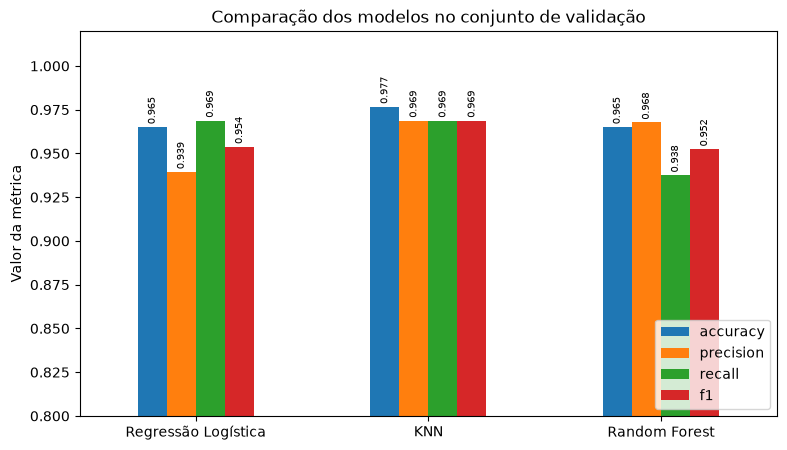

In [14]:
visualizacao.grafico_comparacao_modelos(metricas_validacao)

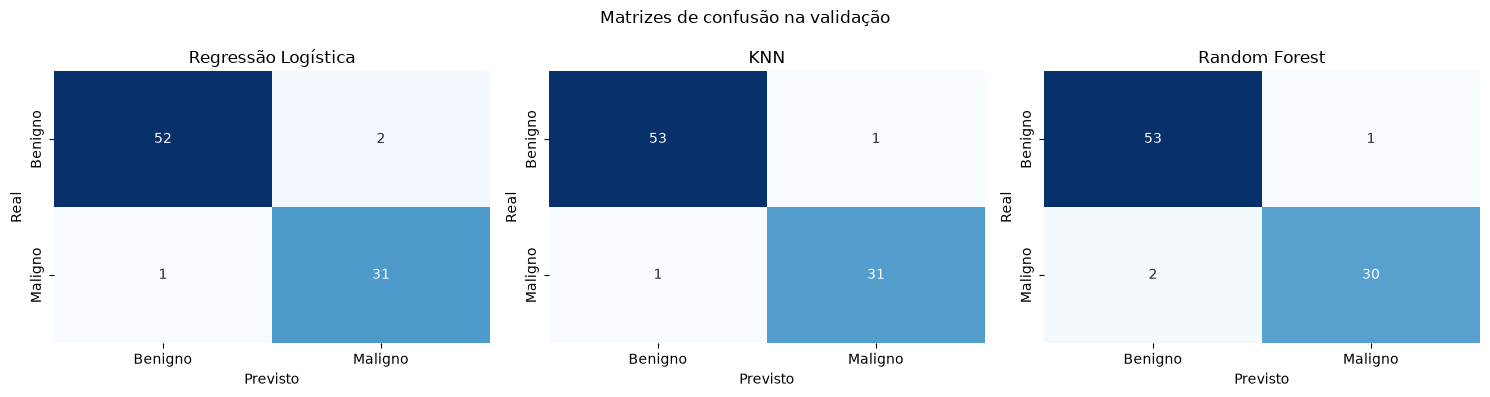

In [15]:
visualizacao.grafico_matrizes_confusao(
    {nome: metricas["matriz_confusao"] for nome, metricas in metricas_validacao.items()},
    "Matrizes de confusão na validação",
    "matrizes_confusao_validacao.png",
)

In [16]:
nome_melhor = escolher_melhor_modelo(metricas_validacao)
modelo_final = modelos[nome_melhor]
nome_melhor

'Regressão Logística'

Regressão Logística e KNN empataram no recall da validação. A Regressão Logística ganhou no desempate porque teve recall bem maior na validação cruzada do treino, o que mostra que ela é mais estável.

## 7. Avaliação final no teste

In [17]:
metricas_teste = avaliar_no_teste(modelo_final, divisao)
metricas_teste

{'accuracy': 0.9884,
 'precision': 1.0,
 'recall': 0.9688,
 'f1': 0.9841,
 'matriz_confusao': [[54, 0], [1, 31]]}

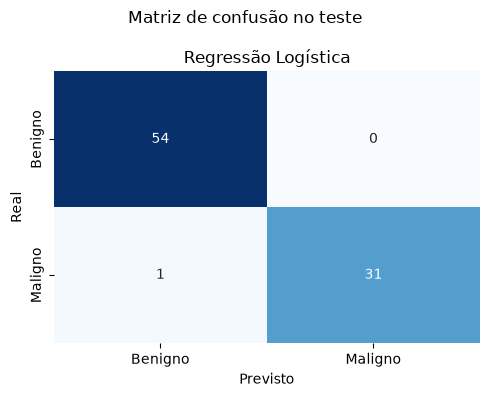

In [18]:
visualizacao.grafico_matrizes_confusao(
    {nome_melhor: metricas_teste["matriz_confusao"]},
    "Matriz de confusão no teste",
    "matriz_confusao_teste.png",
)

No teste o modelo encontrou 31 dos 32 tumores malignos e não teve falso positivo. O resultado ficou próximo do obtido na validação.

## 8. Interpretação

### Importância por permutação

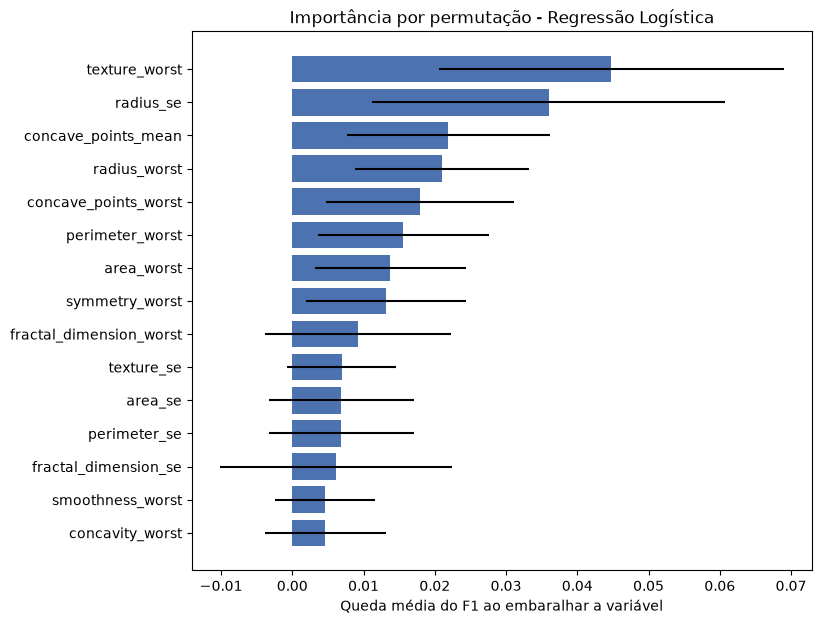

In [19]:
importancia = interpretacao.importancia_por_permutacao(modelo_final, divisao["x_teste"], divisao["y_teste"])
interpretacao.grafico_importancia(importancia, nome_melhor)

### SHAP

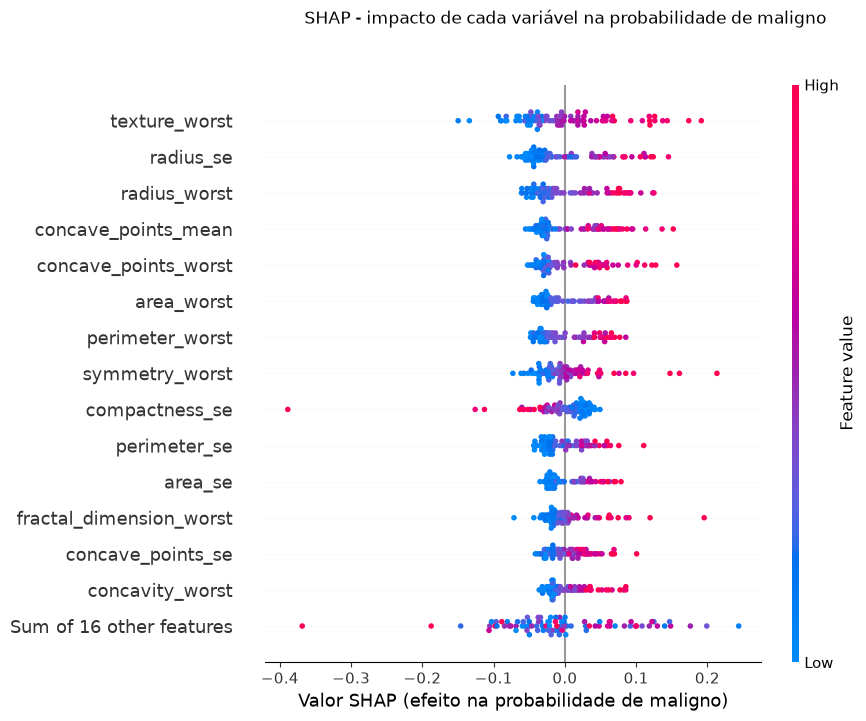

In [20]:
valores_shap = interpretacao.calcular_shap(modelo_final, divisao["x_treino"], divisao["x_teste"])
interpretacao.grafico_shap_resumo(valores_shap)

Cada ponto é um exame. Pontos vermelhos são valores altos da variável; quando estão à direita, empurram a previsão para maligno. Valores altos de tamanho e de irregularidade do núcleo aumentam a probabilidade de malignidade, o que é coerente com a análise exploratória.

### Explicação de um exame

Abaixo, a explicação de um exame maligno do teste. É esse tipo de informação que o médico veria junto com a previsão.

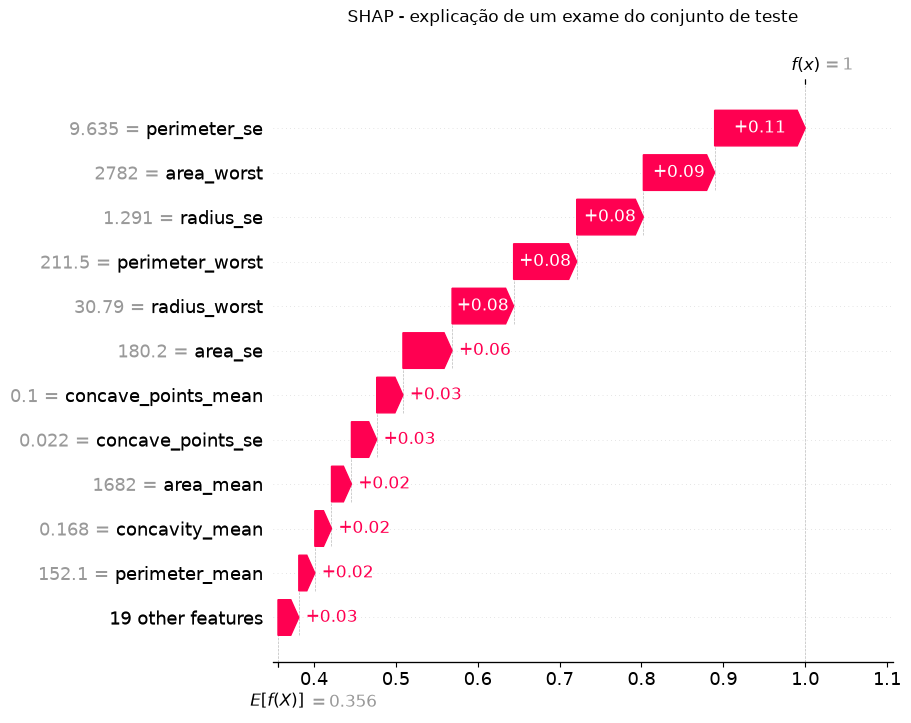

In [21]:
posicao = list(divisao["y_teste"]).index(1)
interpretacao.grafico_shap_paciente(valores_shap, posicao)

## 9. Exemplo de uso na triagem

O modelo devolve a probabilidade de malignidade de cada exame. Na prática os exames com maior probabilidade iriam primeiro para a revisão do médico, que sempre dá a palavra final.

In [22]:
exames = divisao["x_teste"].head(8)
triagem = pd.DataFrame({
    "probabilidade_maligno": modelo_final.predict_proba(exames)[:, 1].round(3),
    "previsao": modelo_final.predict(exames),
    "diagnostico_real": divisao["y_teste"].head(8).values,
}, index=exames.index)
triagem.sort_values("probabilidade_maligno", ascending=False)

,probabilidade_maligno,previsao,diagnostico_real
503,1.000,1,1
7,0.985,1,1
123,0.040,0,0
420,0.008,0,0
371,0.003,0,0
418,0.002,0,0
548,0.001,0,0
534,0.001,0,0


## 10. Conclusão

- O pipeline completo (limpeza, escalonamento, treino, escolha pela validação e teste único) chegou a recall de 96,9% e F1 de 0,984 no teste.
- As variáveis mais importantes fazem sentido clinicamente: tamanho e irregularidade do núcleo.
- O modelo serve como **apoio à triagem**, nunca como diagnóstico final. Antes de uso real precisa ser validado com dados do hospital, porque a base é pequena e vem de um único centro.

O relatório técnico completo está em `reports/relatorio_tecnico.pdf`.